# 02 — Primeiro Classificador: Regressão Logística

No notebook 01, conhecemos o Adult Income e descobrimos que só **23,9%** das pessoas ganham mais de US\$ 50 mil. Também vimos que um "modelo" que sempre responde `<=50K` acertaria 76% das vezes sem aprender nada.

Agora vamos treinar nosso **primeiro classificador**. Neste notebook vamos:
- Separar treino e teste de forma **estratificada**
- Medir o desempenho com a **acurácia** e a **validação cruzada estratificada**
- Criar o **baseline** que sempre chuta a classe mais comum
- Conhecer a **regressão logística**, o "irmão classificador" da regressão linear
- Usar a **matriz de confusão** para ver **como** o modelo erra
- Entender as **probabilidades** que o classificador produz

Por enquanto, vamos usar **só as colunas numéricas**. As categóricas (texto) ficam para o notebook 03.

> Lembrete: execute as células em ordem com `Shift + Enter`. Linhas que começam com `#` são comentários.

## 🎓 Conceito: classificação

No ML-01 o alvo era um **número** (o valor das casas), e o modelo devolvia um número: isso é **regressão**. Aqui o alvo é uma **categoria** (`<=50K` ou `>50K`), e o modelo precisa devolver uma categoria: isso é **classificação**.

O aprendizado continua sendo **supervisionado**: mostramos ao modelo milhares de exemplos **com a resposta certa** e ele aprende um padrão para responder sozinho em exemplos novos.

A diferença está no que o modelo devolve e em como medimos o erro:

| | Regressão (ML-01) | Classificação (ML-02) |
|---|---|---|
| Pergunta | "Quanto vale?" | "Qual grupo?" |
| Previsão | Um número (ex.: US\$ 213 mil) | Uma classe (ex.: `>50K`) e, muitas vezes, uma **probabilidade** (ex.: 72%) |
| Erro | "Errei por quanto?" (MAE, RMSE) | "Acertei ou errei?" e "**que tipo** de erro cometi?" |

Uma analogia: um **termômetro** dá um número (regressão); um **teste de gravidez** dá "sim" ou "não" (classificação).

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Ferramentas novas deste notebook:
from sklearn.model_selection import StratifiedKFold      # validação cruzada que respeita a proporção das classes
from sklearn.model_selection import cross_val_score      # já conhecida do ML-01
from sklearn.model_selection import cross_val_predict    # previsões "fora da dobra" para cada linha
from sklearn.dummy import DummyClassifier                 # baseline de classificação
from sklearn.linear_model import LogisticRegression       # nosso primeiro classificador
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

df = fetch_openml("adult", version=2, as_frame=True).frame

# X: as colunas de entrada (tudo menos o alvo).
X = df.drop(columns="class")

# y: o alvo como 0/1, igual à coluna renda_alta do notebook 01.
# Modelos de classificação aceitam texto como alvo, mas 0/1 deixa as contas e os gráficos mais simples.
y = (df["class"] == ">50K").astype(int)

print("X:", X.shape, "  y:", y.shape)
print(f"Proporção de renda alta (y = 1): {y.mean():.1%}")

X: (48842, 14)   y: (48842,)
Proporção de renda alta (y = 1): 23.9%


## 🎓 Conceito: divisão estratificada

No ML-01, separamos 20% das casas para o **teste** com `train_test_split`, sorteando as linhas ao acaso. Aqui há um cuidado extra: as classes são **desbalanceadas** (24% × 76%).

Num sorteio puramente aleatório, o teste poderia sair, por azar, com 22% ou 26% de renda alta. Isso deixaria treino e teste **diferentes** entre si, e a avaliação ficaria menos justa.

A **divisão estratificada** resolve isso: ela sorteia **separadamente dentro de cada classe**, garantindo que treino e teste tenham **a mesma proporção** de cada classe que os dados completos.

Analogia: para provar uma sopa de legumes, você mexe bem antes de encher a colher. Assim cada colherada tem um pouco de tudo, na mesma proporção da panela.

No scikit-learn, basta passar `stratify=y`.

## 2. Separando o teste (estratificado)

In [2]:
# stratify=y: o sorteio mantém a proporção de 0s e 1s de y nos dois pedaços.
# test_size=0.2 e random_state=42: os mesmos valores do ML-01.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Para comparar: uma divisão SEM estratificação, com várias sementes diferentes.
# Uma "list comprehension" [... for semente in range(10)] cria uma lista repetindo a expressão para cada semente.
proporcoes_sem_estratificar = [
    train_test_split(X, y, test_size=0.2, random_state=semente)[3].mean()   # [3] = o y_test
    for semente in range(10)
]

print(f"Dados completos:      {y.mean():.2%} de renda alta")
print(f"Treino estratificado: {y_train.mean():.2%}  ({len(y_train)} pessoas)")
print(f"Teste estratificado:  {y_test.mean():.2%}  ({len(y_test)} pessoas)")
print(f"\nSem estratificar, o teste variou de {min(proporcoes_sem_estratificar):.2%} "
      f"a {max(proporcoes_sem_estratificar):.2%} conforme a semente.")

Dados completos:      23.93% de renda alta
Treino estratificado: 23.93%  (39073 pessoas)
Teste estratificado:  23.93%  (9769 pessoas)

Sem estratificar, o teste variou de 23.49% a 24.41% conforme a semente.


**Conclusão:** com a estratificação, treino (39.073 pessoas) e teste (9.769 pessoas) ficaram **exatamente** com a mesma proporção dos dados completos: **23,93%** de renda alta. Sem estratificar, a proporção no teste variou de **23,49% a 24,41%** conforme a semente.

Com quase 10 mil pessoas no teste, essa variação é pequena. Mas em datasets menores, ou com classes mais raras (uma doença que atinge 1% das pessoas, por exemplo), ela pode ser enorme. Por isso, **em classificação, estratificar é o padrão**.

## 🎓 Conceito: acurácia

A métrica mais simples de classificação é a **acurácia**: a porcentagem de previsões **certas**.

$$\text{acurácia} = \frac{\text{número de acertos}}{\text{número total de previsões}}$$

Ela é fácil de entender ("o modelo acerta 80% das vezes"), mas tem um ponto fraco grave com classes desbalanceadas, que vamos ver já já.

## 🎓 Conceito: validação cruzada estratificada

No ML-01 (notebook 05), aprendemos a **validação cruzada K-Fold**: dividir o treino em K dobras e usar cada uma, uma vez, como validação. Assim, cada decisão se baseia em K resultados, e não em uma única divisão "sortuda".

Para classificação, usamos a versão **estratificada**: o `StratifiedKFold` monta as dobras de forma que **cada dobra** tenha a mesma proporção de classes (24% × 76%). É a mesma ideia da seção 2, aplicada a cada dobra.

Vamos usar sempre a mesma configuração: **5 dobras, embaralhadas, com `random_state=42`**. O **teste** fica guardado até o final da trilha.

In [3]:
# Mesma receita do ML-01, mas com StratifiedKFold no lugar do KFold.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Conferindo: qual a proporção de renda alta na dobra de validação de cada rodada?
# cv.split(X, y) precisa receber o y, porque é ele que define as classes a equilibrar.
for rodada, (pos_treino, pos_val) in enumerate(cv.split(X_train, y_train), start=1):
    print(f"Dobra {rodada}: {len(pos_val)} pessoas na validação, {y_train.iloc[pos_val].mean():.2%} de renda alta")

Dobra 1: 7815 pessoas na validação, 23.93% de renda alta
Dobra 2: 7815 pessoas na validação, 23.93% de renda alta
Dobra 3: 7815 pessoas na validação, 23.93% de renda alta
Dobra 4: 7814 pessoas na validação, 23.92% de renda alta
Dobra 5: 7814 pessoas na validação, 23.93% de renda alta


**Conclusão:** as 5 dobras de validação têm ~7.815 pessoas cada, todas com **23,92% a 23,93%** de renda alta. Cada rodada da validação cruzada enxerga o mesmo "retrato" do problema.

## 3. O baseline: sempre chutar a classe mais comum

No ML-01, o baseline previa **sempre a média** dos preços. O equivalente na classificação é prever **sempre a classe mais frequente**. O scikit-learn tem isso pronto: o `DummyClassifier`.

Qualquer modelo de verdade precisa **vencer** esse baseline. Se não vencer, ele não aprendeu nada útil.

In [4]:
# As 5 colunas numéricas que fazem sentido usar (o notebook 01 mostrou que fnlwgt não ajuda).
colunas_numericas = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]

# strategy="most_frequent": ignora as colunas e responde sempre a classe mais comum do treino.
baseline = DummyClassifier(strategy="most_frequent")

acuracias_baseline = cross_val_score(
    baseline, X_train[colunas_numericas], y_train,
    cv=cv,
    scoring="accuracy",   # na acurácia, maior é melhor (não precisa trocar sinal como no MAE)
)
print("Acurácia por dobra:", acuracias_baseline.round(4))
print(f"Acurácia do baseline: {acuracias_baseline.mean():.2%} ± {acuracias_baseline.std():.2%}")

Acurácia por dobra: [0.7607 0.7607 0.7607 0.7608 0.7607]
Acurácia do baseline: 76.07% ± 0.00%


**Conclusão:** o baseline acerta **76,07%** das vezes, com desvio padrão **zero**: em todas as dobras ele responde `<=50K` para todo mundo, e o resultado é simplesmente a proporção de `<=50K` na dobra.

Esse é o número que precisamos vencer. Repare como ele parece alto: alguém desatento diria "76% de acerto, ótimo modelo!", sem perceber que ele **nunca** encontra uma única pessoa de renda alta.

## 🎓 Conceito: regressão logística

Apesar do nome, a **regressão logística** é um modelo de **classificação**. Ela é a "versão classificadora" da regressão linear do ML-01, e funciona em dois passos:

1. **Calcula uma pontuação** igualzinho à regressão linear: soma cada coluna multiplicada por um coeficiente, mais o intercepto.
   $$z = b_0 + b_1 \cdot \text{idade} + b_2 \cdot \text{escolaridade} + \dots$$
   Essa pontuação pode ser qualquer número: −7, 0, 3,2...

2. **Espreme a pontuação entre 0 e 1** com a função **sigmoide** (em forma de "S"):
   $$p = \frac{1}{1 + e^{-z}}$$
   - pontuação muito negativa → $p$ perto de 0
   - pontuação zero → $p = 0{,}5$
   - pontuação muito positiva → $p$ perto de 1

O resultado $p$ é interpretado como a **probabilidade** de a pessoa ser da classe 1 (renda alta). Para decidir a classe, o modelo usa um **limiar** (*threshold*): se $p \geq 0{,}5$, prevê `>50K`; senão, `<=50K`.

Analogia: um médico soma vários sinais (febre, tosse, idade...) numa "pontuação de risco" e depois traduz essa pontuação numa chance de 0% a 100%. A regressão logística faz exatamente isso, e **aprende sozinha** quanto cada sinal pesa.

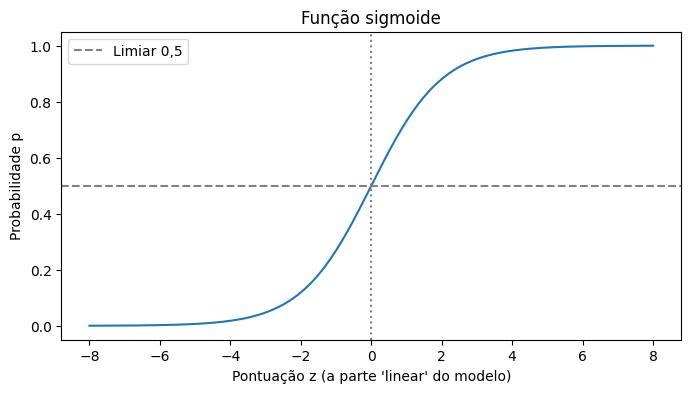

In [5]:
# Vamos ver a sigmoide: para cada pontuação z, qual probabilidade ela gera?
z = np.linspace(-8, 8, 200)       # 200 números igualmente espaçados entre -8 e 8
p = 1 / (1 + np.exp(-z))          # np.exp(x) é e elevado a x; a conta é feita para os 200 valores de uma vez

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(z, p)
ax.axhline(0.5, color="gray", linestyle="--", label="Limiar 0,5")
ax.axvline(0, color="gray", linestyle=":")
ax.set_xlabel("Pontuação z (a parte 'linear' do modelo)")
ax.set_ylabel("Probabilidade p")
ax.set_title("Função sigmoide")
ax.legend()
plt.show()

**Conclusão:** a sigmoide transforma qualquer pontuação num número entre 0 e 1. Ela é quase plana nas pontas (abaixo de −5 ou acima de +5, a probabilidade já está praticamente em 0 ou 1) e muda rápido perto de zero, onde cruza o limiar de 0,5.

## 4. Regressão logística com uma variável: escolaridade

Para enxergar o modelo funcionando, vamos começar com **uma única** coluna, a escolaridade (`education-num`), que tinha a maior correlação com o alvo no notebook 01.

Para desenhar o gráfico, treinamos o modelo uma vez com todo o treino. A **avaliação** continua sendo feita com validação cruzada.

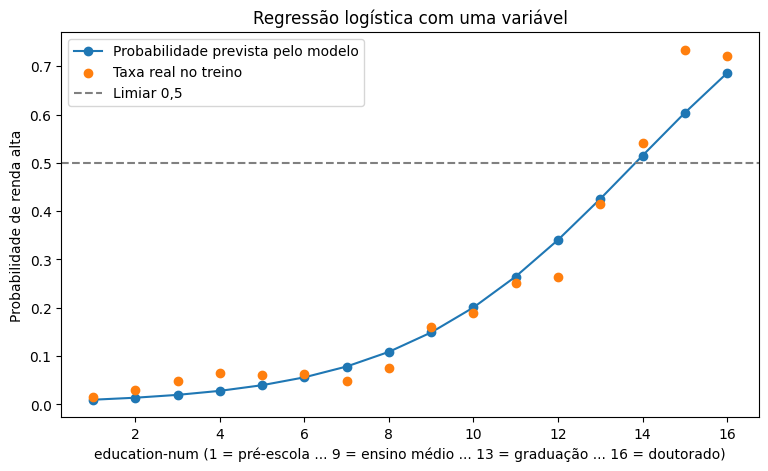

Coeficiente: 0.361   Intercepto: -4.988
Níveis previstos como >50K: [14, 15, 16]


In [6]:
modelo_escolaridade = LogisticRegression()
modelo_escolaridade.fit(X_train[["education-num"]], y_train)   # [["..."]] = tabela com 1 coluna

# predict_proba devolve DUAS colunas: a probabilidade da classe 0 e a da classe 1.
# [:, 1] pega todas as linhas (:) da coluna 1, ou seja, a probabilidade de renda alta.
niveis = pd.DataFrame({"education-num": np.arange(1, 17)})
prob_modelo = modelo_escolaridade.predict_proba(niveis)[:, 1]

# A taxa REAL de renda alta em cada nível de escolaridade (no treino), para comparar.
taxa_real = y_train.groupby(X_train["education-num"]).mean()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(niveis["education-num"], prob_modelo, marker="o", label="Probabilidade prevista pelo modelo")
ax.scatter(taxa_real.index, taxa_real.values, color="tab:orange", zorder=3, label="Taxa real no treino")
ax.axhline(0.5, color="gray", linestyle="--", label="Limiar 0,5")
ax.set_xlabel("education-num (1 = pré-escola ... 9 = ensino médio ... 13 = graduação ... 16 = doutorado)")
ax.set_ylabel("Probabilidade de renda alta")
ax.set_title("Regressão logística com uma variável")
ax.legend()
plt.show()

print(f"Coeficiente: {modelo_escolaridade.coef_[0, 0]:.3f}   Intercepto: {modelo_escolaridade.intercept_[0]:.3f}")

# Quais níveis o modelo classifica como renda alta? (probabilidade >= 0,5)
print("Níveis previstos como >50K:", niveis.loc[prob_modelo >= 0.5, "education-num"].tolist())

In [7]:
acuracias_escolaridade = cross_val_score(
    LogisticRegression(), X_train[["education-num"]], y_train, cv=cv, scoring="accuracy"
)
print(f"Acurácia (só escolaridade): {acuracias_escolaridade.mean():.2%} ± {acuracias_escolaridade.std():.2%}")
print(f"Acurácia (baseline):        {acuracias_baseline.mean():.2%}")

Acurácia (só escolaridade): 77.87% ± 0.15%
Acurácia (baseline):        76.07%


**Conclusão:** a curva azul é a sigmoide "esticada" sobre a escolaridade, e ela acompanha bem os pontos laranja da taxa real. Ela sobe devagar nos níveis baixos (1% a 8%) e acelera a partir do ensino médio. Nas pontas há desvios: o modelo **subestima** os níveis mais altos (prevê 60% para `Prof-school`, nível 15, onde a taxa real é 73%) e **superestima** o nível 12 (34% contra 26%). Uma única curva em "S" não consegue seguir todos os detalhes.

O coeficiente positivo (**0,361**) diz que cada nível a mais de escolaridade aumenta a pontuação $z$ e, portanto, a chance de renda alta.

O ponto mais importante: a curva só passa de 0,5 a partir do **mestrado** (níveis 14, 15 e 16). Então o modelo prevê `>50K` só para mestres e doutores e `<=50K` para todo o resto, inclusive para quem tem graduação. Mesmo assim, a acurácia subiu de 76,07% para **77,87%**: um ganho pequeno, mas real.

## 5. Regressão logística com todas as colunas numéricas

Agora usamos as 5 colunas numéricas. Como as colunas estão em escalas muito diferentes (idade vai até 90, `capital-gain` até 99.999), colocamos o `StandardScaler` antes do modelo, dentro de um `Pipeline`, como aprendemos no ML-01.

Na regressão logística, a padronização ajuda duas coisas: o algoritmo de treino **converge** mais facilmente, e os **coeficientes ficam comparáveis** entre si (seção 8).

In [8]:
logistica = Pipeline([
    ("padronizar", StandardScaler()),
    ("modelo", LogisticRegression()),
])

acuracias_logistica = cross_val_score(
    logistica, X_train[colunas_numericas], y_train, cv=cv, scoring="accuracy"
)
print("Acurácia por dobra:", acuracias_logistica.round(4))
print(f"Acurácia (5 numéricas): {acuracias_logistica.mean():.2%} ± {acuracias_logistica.std():.2%}")

# Comparação pareada (ML-01, notebook 05): a logística vence o baseline em quantas dobras?
vitorias = (acuracias_logistica > acuracias_baseline).sum()
print(f"Venceu o baseline em {vitorias} de 5 dobras")

Acurácia por dobra: [0.8097 0.8237 0.8104 0.8096 0.8105]
Acurácia (5 numéricas): 81.28% ± 0.55%
Venceu o baseline em 5 de 5 dobras


**Conclusão:** com as 5 colunas numéricas, a acurácia subiu para **81,28% ± 0,55%**, cerca de **5 pontos acima do baseline**. A logística venceu o baseline nas **5 dobras**, então o ganho é consistente.

Mas **81% de acerto é bom ou ruim?** A acurácia não diz **onde** estão os erros. Para isso precisamos de uma ferramenta nova.

## 🎓 Conceito: matriz de confusão

A **matriz de confusão** é uma tabela que separa os acertos e os erros **por tipo**. Na classificação binária, ela tem 4 casas:

| | Previsto `<=50K` (0) | Previsto `>50K` (1) |
|---|---|---|
| **Real `<=50K` (0)** | ✅ **Verdadeiro negativo (VN)** | ❌ **Falso positivo (FP)** |
| **Real `>50K` (1)** | ❌ **Falso negativo (FN)** | ✅ **Verdadeiro positivo (VP)** |

- **Positivo** é a classe que estamos "procurando" (aqui, renda alta = 1). **Negativo** é a outra.
- **Verdadeiro/Falso** diz se o modelo acertou ou errou.
- **Falso positivo:** o modelo disse "renda alta", mas era renda baixa. É um **alarme falso**.
- **Falso negativo:** o modelo disse "renda baixa", mas era renda alta. É um caso **que passou despercebido**.

Analogia: um detector de fumaça. Apitar sem fogo é um **falso positivo** (chato, mas inofensivo). **Não** apitar com fogo de verdade é um **falso negativo** (perigoso). Os dois são "erros", mas têm consequências muito diferentes, e a acurácia trata os dois como iguais.

Para montar a matriz sem tocar no teste, usamos `cross_val_predict`: ele faz a validação cruzada e devolve, para **cada pessoa do treino**, a previsão feita pelo modelo que **não** a viu no treino (o modelo da rodada em que ela estava na dobra de validação).

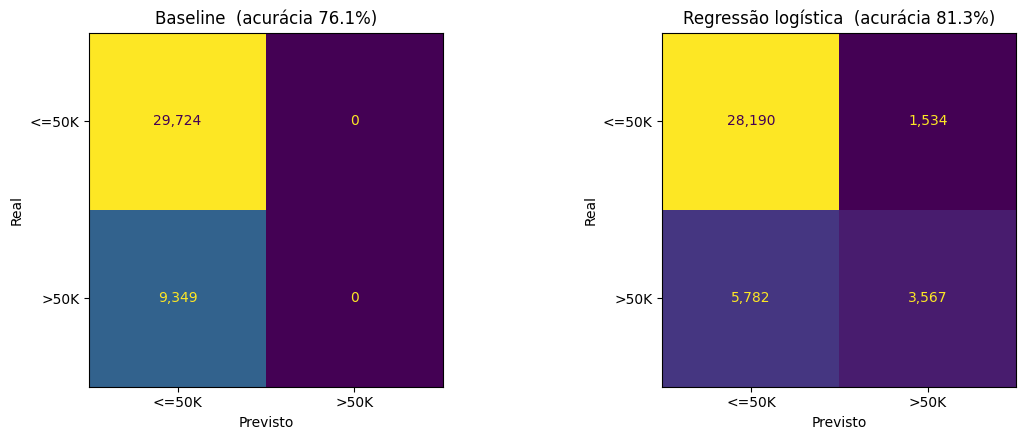

In [9]:
# Uma previsão "honesta" para cada uma das 39 mil pessoas do treino.
prev_baseline = cross_val_predict(baseline, X_train[colunas_numericas], y_train, cv=cv)
prev_logistica = cross_val_predict(logistica, X_train[colunas_numericas], y_train, cv=cv)

# ConfusionMatrixDisplay desenha a matriz a partir dos valores reais e previstos.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, previsoes, titulo in zip(axes, [prev_baseline, prev_logistica], ["Baseline", "Regressão logística"]):
    ConfusionMatrixDisplay.from_predictions(
        y_train, previsoes,
        display_labels=["<=50K", ">50K"],
        values_format=",",     # separador de milhar nos números
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"{titulo}  (acurácia {accuracy_score(y_train, previsoes):.1%})")
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

In [10]:
# confusion_matrix devolve a mesma tabela como um array. .ravel() "achata" em 4 números, na ordem VN, FP, FN, VP.
vn, fp, fn, vp = confusion_matrix(y_train, prev_logistica).ravel()
total_positivos = vp + fn   # todas as pessoas que REALMENTE têm renda alta

print(f"Pessoas com renda alta no treino:  {total_positivos:,}")
print(f"  ... encontradas pelo modelo (VP): {vp:,}  ({vp / total_positivos:.1%})")
print(f"  ... que passaram despercebidas (FN): {fn:,}  ({fn / total_positivos:.1%})")
print(f"\nPrevisões '>50K' feitas pelo modelo: {vp + fp:,}")
print(f"  ... corretas (VP): {vp:,}  ({vp / (vp + fp):.1%})")
print(f"  ... alarmes falsos (FP): {fp:,}  ({fp / (vp + fp):.1%})")

Pessoas com renda alta no treino:  9,349
  ... encontradas pelo modelo (VP): 3,567  (38.2%)
  ... que passaram despercebidas (FN): 5,782  (61.8%)

Previsões '>50K' feitas pelo modelo: 5,101
  ... corretas (VP): 3,567  (69.9%)
  ... alarmes falsos (FP): 1,534  (30.1%)


**Conclusão:** a matriz de confusão revela o que a acurácia escondia:
- O **baseline** acerta todos os 29.724 casos `<=50K` e erra **todos** os 9.349 casos `>50K`. A acurácia de 76% vem inteira da classe majoritária.
- A **regressão logística** encontra só **3.567 das 9.349** pessoas de renda alta (**38,2%**). As outras **5.782 (61,8%) passam despercebidas**: o modelo diz `<=50K` para elas.
- Quando o modelo diz `>50K`, ele acerta em **69,9%** das vezes (3.567 de 5.101), e 30,1% são alarmes falsos.

Ou seja, a acurácia de 81% esconde um modelo que **deixa escapar a maioria** das pessoas que queríamos encontrar. Os erros estão concentrados na classe **minoritária**. No notebook 04, os dois percentuais que calculamos aqui vão ganhar nomes próprios: **recall** (38,2%) e **precisão** (69,9%).

## 6. Por que o modelo quase não prevê `>50K`? As probabilidades

O modelo não devolve só a classe: com `predict_proba`, ele devolve a **probabilidade** de renda alta para cada pessoa. A classe prevista é só essa probabilidade comparada com o limiar 0,5.

Vamos ver como as probabilidades se distribuem para quem **realmente** ganha mais e para quem ganha menos.

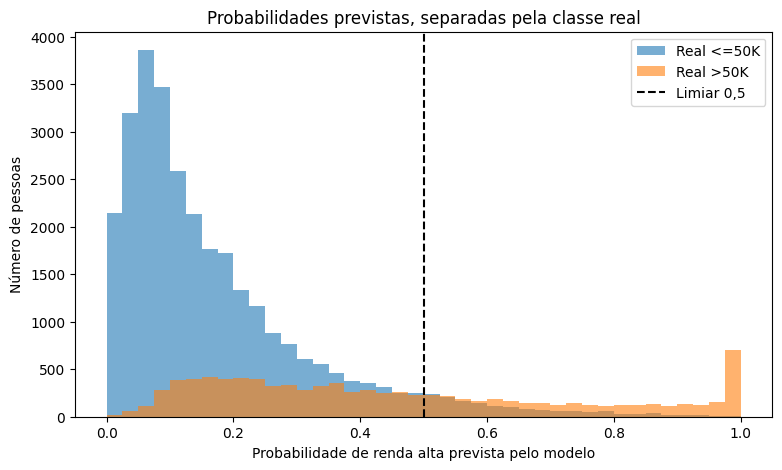

Entre quem REALMENTE ganha >50K:
  probabilidade mediana prevista: 39.1%
  com probabilidade abaixo de 0,5: 61.8%


In [11]:
# method="predict_proba": em vez da classe, o cross_val_predict devolve as probabilidades.
prob_logistica = cross_val_predict(
    logistica, X_train[colunas_numericas], y_train, cv=cv, method="predict_proba"
)[:, 1]

fig, ax = plt.subplots(figsize=(9, 5))
bins = np.linspace(0, 1, 41)   # 40 faixas de largura 0,025
# y_train == 0 gera um filtro True/False; prob_logistica[filtro] pega só as probabilidades dessas pessoas.
ax.hist(prob_logistica[y_train == 0], bins=bins, alpha=0.6, label="Real <=50K")
ax.hist(prob_logistica[y_train == 1], bins=bins, alpha=0.6, label="Real >50K")
ax.axvline(0.5, color="black", linestyle="--", label="Limiar 0,5")
ax.set_xlabel("Probabilidade de renda alta prevista pelo modelo")
ax.set_ylabel("Número de pessoas")
ax.set_title("Probabilidades previstas, separadas pela classe real")
ax.legend()
plt.show()

prob_renda_alta = pd.Series(prob_logistica[y_train == 1])
print(f"Entre quem REALMENTE ganha >50K:")
print(f"  probabilidade mediana prevista: {prob_renda_alta.median():.1%}")
print(f"  com probabilidade abaixo de 0,5: {(prob_renda_alta < 0.5).mean():.1%}")

**Conclusão:** o histograma mostra por que o modelo deixa escapar tanta gente:
- As pessoas de renda **baixa** (azul) se concentram em probabilidades baixas, entre 0 e 0,3. O modelo as reconhece bem.
- As pessoas de renda **alta** (laranja) ficam **espalhadas** por todo o eixo. A probabilidade mediana prevista para elas é de só **39,1%**, e **61,8%** delas ficam abaixo do limiar 0,5. É exatamente a mesma porcentagem de falsos negativos da seção anterior.
- O pico laranja perto de 1,0 tem ~700 pessoas, e quase todas (99%) têm `capital-gain` positivo, com mediana de US\$ 15 mil. Para quem tem ganho de capital alto, o modelo tem quase certeza.

Duas lições aqui:
1. Com só 5 colunas numéricas, muitas pessoas de renda alta são **parecidas** com as de renda baixa (mesma idade, mesmas horas, sem ganho de capital). O modelo não tem informação para separá-las. As colunas categóricas, como estado civil e profissão, que foram as mais informativas no notebook 01, devem ajudar muito.
2. O limiar **0,5 não é obrigatório**. Se o baixássemos para 0,3, por exemplo, mais pessoas de renda alta seriam encontradas, ao custo de mais alarmes falsos. Vamos explorar essa troca no notebook 04.

## 7. O que o modelo aprendeu? Os coeficientes

Como as colunas foram padronizadas, cada coeficiente mede o efeito de **aumentar a coluna em 1 desvio padrão**, e eles podem ser comparados entre si:
- **Positivo:** aumenta a pontuação $z$ e, portanto, a probabilidade de renda alta.
- **Negativo:** diminui.
- Quanto maior o valor (em módulo), maior o efeito.

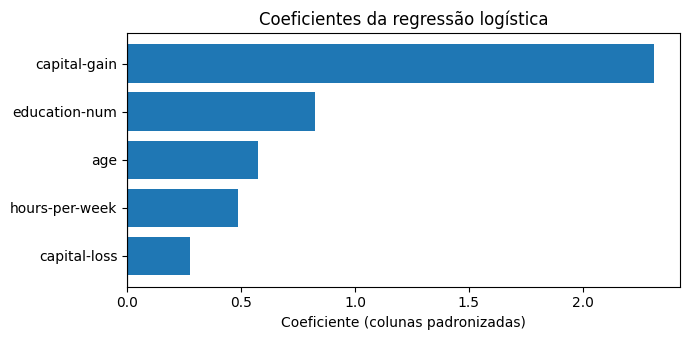

capital-gain      2.311
education-num     0.824
age               0.577
hours-per-week    0.488
capital-loss      0.277
dtype: float64

In [12]:
logistica.fit(X_train[colunas_numericas], y_train)   # treina uma vez com todo o treino para olhar os coeficientes

# named_steps acessa uma etapa do pipeline pelo nome que demos a ela.
coeficientes = pd.Series(
    logistica.named_steps["modelo"].coef_[0],    # coef_ tem formato (1, 5); [0] pega a única linha
    index=colunas_numericas,
).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(coeficientes.index, coeficientes.values)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coeficiente (colunas padronizadas)")
ax.set_title("Coeficientes da regressão logística")
plt.tight_layout()
plt.show()

coeficientes.sort_values(ascending=False).round(3)

**Conclusão:** - **`capital-gain` tem de longe o maior coeficiente (2,31).** Lembre do notebook 01: 92% das pessoas têm ganho zero, e quem tem ganho alto quase sempre ganha mais de 50 mil. Como a coluna tem uma cauda enorme (até 99.999), um desvio padrão a mais já empurra a probabilidade para perto de 1.
- Em seguida vêm **escolaridade (0,82)**, **idade (0,58)** e **horas por semana (0,49)**, todas positivas, como a análise exploratória sugeria.
- **`capital-loss` também é positivo (0,28)**, o que parece estranho: perder dinheiro aumenta a chance de renda alta? Faz sentido quando lembramos que só quem **tem investimentos** pode ter perdas com eles, e quem investe tende a ganhar mais.

⚠️ Um limite importante: a logística trata a idade como uma **reta** ("mais velho, mais renda"). Mas o notebook 01 mostrou uma curva em "U" invertido, com queda depois dos 55 anos. Esse modelo não consegue capturar essa queda, um problema que os modelos de árvore do notebook 05 resolvem naturalmente.

## 8. Usando o modelo para uma pessoa

Vamos ver o modelo em ação com duas pessoas inventadas.

In [13]:
# Um DataFrame criado a partir de um dicionário: cada chave é uma coluna, cada lista são os valores.
pessoas = pd.DataFrame({
    "age":            [25, 50],
    "education-num":  [9, 14],      # 9 = ensino médio, 14 = mestrado
    "capital-gain":   [0, 0],
    "capital-loss":   [0, 0],
    "hours-per-week": [40, 50],
}, index=["Ana (25 anos, ensino médio)", "Bruno (50 anos, mestrado)"])

pessoas["probabilidade >50K"] = logistica.predict_proba(pessoas[colunas_numericas])[:, 1]
pessoas["previsão"] = np.where(logistica.predict(pessoas[colunas_numericas]) == 1, ">50K", "<=50K")
pessoas

,age,education-num,capital-gain,capital-loss,hours-per-week,probabilidade >50K,previsão
"Ana (25 anos, ensino médio)",25,9,0,0,40,0.063,<=50K
"Bruno (50 anos, mestrado)",50,14,0,0,50,0.587,>50K


**Conclusão:** a Ana, de 25 anos e com ensino médio, tem só **6,3%** de probabilidade de renda alta. O Bruno, de 50 anos, com mestrado e 50 horas por semana, tem **58,7%** e é classificado como `>50K`, mas por pouco.

Repare como a **probabilidade** é mais informativa do que a classe sozinha. "58,7%" diz que o modelo está **inseguro** sobre o Bruno, enquanto "6,3%" mostra que ele está bastante confiante sobre a Ana. Se olhássemos só para `>50K` e `<=50K`, perderíamos essa informação.

## 9. Resumo e próximos passos

**Resultados (validação cruzada no treino)**

| Modelo | Acurácia | Pessoas de renda alta encontradas |
|---|---|---|
| Baseline (sempre `<=50K`) | 76,07% | 0% |
| Logística, só escolaridade | 77,87% | — |
| Logística, 5 numéricas | **81,28% ± 0,55%** | 38,2% |

**Conceitos que você aprendeu**
- **Classificação** × regressão: prever uma classe (e uma probabilidade) em vez de um número.
- **Divisão estratificada** e **validação cruzada estratificada** (`StratifiedKFold`).
- **Acurácia**, e por que ela engana quando as classes são desbalanceadas.
- **Baseline de classificação** (`DummyClassifier`).
- **Regressão logística**: pontuação linear + **sigmoide** = probabilidade; **limiar** de 0,5 para decidir a classe.
- **Matriz de confusão**: verdadeiros/falsos positivos e negativos.
- **Probabilidades** previstas e o que elas revelam sobre a confiança do modelo.

**Python novo:** `stratify=`, list comprehension, `np.linspace`, `np.exp`, `predict_proba` e o fatiamento `[:, 1]`, `cross_val_predict` (inclusive com `method="predict_proba"`), `ConfusionMatrixDisplay`, `.ravel()` e `named_steps`.

**Os problemas que ficaram**
- ⚠️ O modelo usa **só 5 das 13 colunas** úteis. As **categóricas** (estado civil, profissão, sexo...) ficaram de fora, e a análise exploratória mostrou que elas estão entre as mais informativas.
- ⚠️ O modelo **deixa escapar 62%** das pessoas de renda alta.
- ⚠️ A **acurácia** não é uma boa bússola para este problema.

**Próximo notebook (03):** pré-processamento de colunas categóricas. Vamos aprender o **one-hot encoding**, tratar os **valores ausentes** como uma categoria própria, agrupar **categorias raras** e juntar tudo num `ColumnTransformer` dentro do `Pipeline`. Depois disso, a regressão logística vai poder usar **todas** as colunas.